#### Opgaver i eksperimenter

#### Opgave 1 - Beregning af inertimoment
Inertimomentet af et legeme for rotation er analogt til massen af et legeme for rotation. Det bliver behandlet senere i kurset.
Inertimoment betegnes med $I$ og dimensionen af inertimoment er $[I]=\text{ML}^2$.

Inertimomentet, $I$, for en hul cylinder afhænger af dens masse $m$, dens ydre radius $r_1$ og dens indre radius $r_2$, dvs.
$$I=f\left(m,r_1,r_2\right)$$

Data for 20 forskellige hule cylindre beregnes nedenfor, værdierne ligger i *numpy* arrays 
med navnene *m_values*, *r1_values*, *2_values* og *I_values*.
Data har tilføjet støj.

Bestem en model for inertimomentberegningen.

In [ ]:
import numpy as np
rnd = np.random.default_rng(67347683476837638476843)
N = 20
m_values = rnd.uniform(low=0.050,high=1.50,size=N)
r2_values = rnd.uniform(low=0.020,high=0.20,size=N)
r1_values = r2_values + rnd.uniform(low=0.020,high=0.20,size=N)
I_values = 1/2 * m_values * (r1_values**2+r2_values**2)
I_values = I_values + rnd.normal(loc=0.0,scale=0.02*I_values,size=N)

In [2]:
# L = r1
# I/mr_1^2 = f(m/m,r_1/r_1,r_2/r_1)

pi_1 = I_values / (m_values * r1_values**2)
pi_2 = r2_values / r1_values

pi_1, pi_2

(array([0.68691739, 0.84453029, 0.57437387, 0.58834966, 0.71263638,
        0.57848607, 0.80308776, 0.83357433, 0.77023868, 0.53434516,
        0.58542181, 0.53756074, 0.5151454 , 0.66169719, 0.66481221,
        0.56810032, 0.52546494, 0.61065378, 0.55456864, 0.64864095]),
 array([0.58602698, 0.82945402, 0.38713614, 0.39813796, 0.67725749,
        0.41225708, 0.77969155, 0.84165702, 0.74602513, 0.19925622,
        0.40806583, 0.23620737, 0.17918229, 0.53936938, 0.57278421,
        0.34682715, 0.20557311, 0.473641  , 0.30228816, 0.55795734]))

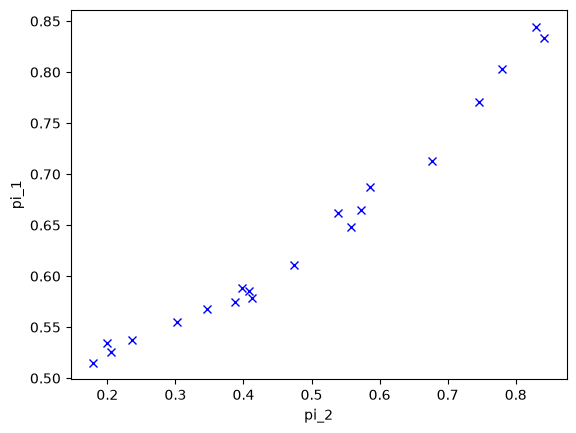

In [4]:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(pi_2,pi_1, 'bx')
plt.xlabel('pi_2')
plt.ylabel('pi_1')
plt.show()

In [15]:
from scipy.optimize import curve_fit

def f(x,A,B,C):
    return A + B*x + C*x**2
params,cov = curve_fit(f,pi_2,pi_1)

params, np.sqrt(np.diag(cov))

(array([0.5049204 , 0.01507042, 0.46073814]),
 array([0.01155242, 0.05031524, 0.04864731]))

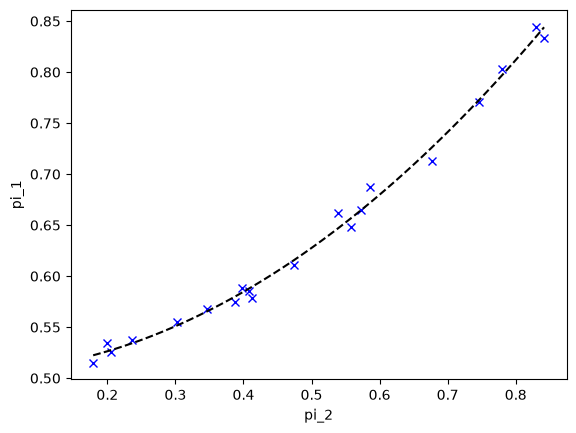

In [17]:
plt.figure()
plt.plot(pi_2,pi_1, 'bx')
pi_2 = np.linspace(min(pi_2),max(pi_2),100)
plt.plot(pi_2,f(pi_2,*params), 'k--')
plt.xlabel('pi_2')
plt.ylabel('pi_1')
plt.show()

Så følgende kan approximeres ud fra usikkerhederne
a = 0.5
b = 0
c = 0.5

Så det er I/mr1^2=a+b(r2/r1)**2 => I=amr1**2 + bmr2**2 og da at a og b er 0.5, da ganger jeg uden for parantes så

I = m/2(r1**2 + r2**2)

####  Opgave 2 - Kinematik

Vi betragter den fysiske situation hvor et legeme til tiden, $t=0$, har starthastigheden $v_0$. Efter et tidsrum, $t$, med den konstante acceleration, $a$, har legemet sluthastigheden, $v$.

Vi ønsker at undersøge hvordan starthastigheden afhænger af accelerationen, tiden og sluthastigheden, dvs. modellen vi forsøger at finde er

>$v_0 = f(a,t,v)$

Undersøg modellen med data givet længere nede. 

Nedenfor er vist seks målte datapunkter for tid, acceleration, starthastighed og sluthastighed. Alle er i SI enheder.
Data hører sammen, så *t[0]*, *a[0]*, *v0[0]*, og *v[0]* stammer fra samme måling, etc.

In [18]:
import numpy as np
t = np.array([0.363,1.761,1.956,2.246,1.256,0.110])
a = np.array([-0.168,-0.953,-1.093,-0.555,0.691,-0.446])
v0 = np.array([0.341,4.652,2.767,3.523,0.058,-2.298])
v = np.array([0.292,3.063,0.552,2.163,0.664,-2.178])

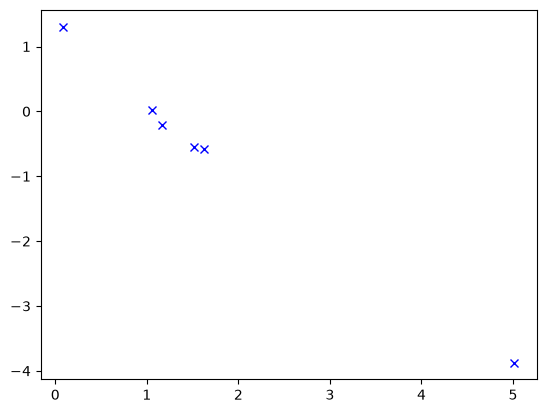

In [ ]:
pi_2 = v0 / v
pi_1 = a*t/v

plt.figure()
plt.plot(pi_2,pi_1,'bx')

In [ ]:
# Det er linært
import uncertainties as unc
def f(x, A, B):
    return A + B*x
params,cov=curve_fit(f,pi_2,pi_1)
display(params)
display(np.sqrt(np.diag(cov)))
A = unc.ufloat(params[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(params[1],np.sqrt(np.diag(cov))[1])
display(A,B)

array([ 1.12668474, -1.01586556])

array([0.1084748 , 0.04655734])

1.1266847359130638+/-0.10847480211046108

-1.015865556290665+/-0.04655733573778047

Med usikkerheder approximeres A=1 & B=-1
Da modellen er a+bx da er modellen

v0/v = -at/v + 1
v0 = -at+v

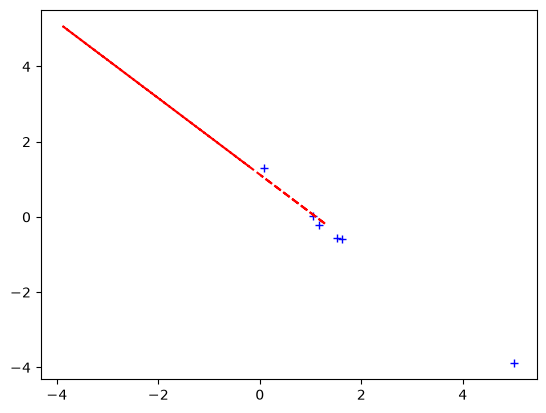

In [ ]:
plt.plot(pi_2,pi_1,'b+')
plt.plot(pi_1,f(pi_1,*params),'r--')
plt.show()

####  Opgave 3 - Flyvetur gennem Jordens indre

Vi forestiller os at der er boret en tunnel gennem Jorden, startende ved  nordpolen og sluttende ved sydpolen.
Vi slipper et legeme fra hvile lige over tunnellens åbning.
Legemet vil nu falde hele vejen gennem tunnellen og komme tilbage igen.
Hele turen tager tiden, $T$.
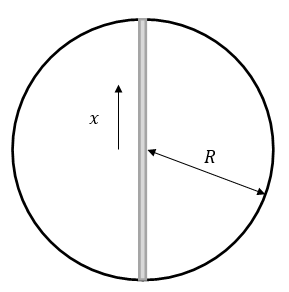

Vi ønsker at undersøge hvordan tiden for turen, $T$, afhænger af Jordens masse, $M$, Jordens radius, $R$ samt
gravitationskonstanten, $G$, dvs. at vi søger modellen

>$T = f(M,R,G)$

Graviationskonstanten har dimensionen, $[G]=\text{ M}^{-1}\text{L}^3\text{T}^{-2}$.

>a) Bestem naturlige skalaer for masse, længde og tid.

>b) Bestem modellen. (Der vil indgå en ukendt konstant.)

Jordens radius er $R=6370\text{ km}$, Jordens masse er $M=5.97\cdot 10^{24}\text{ kg}$
og gravitationskonstanten er $G=6.674\cdot 10^{-11}\text{ kg}^{-1}\text{m}^3\text{s}^{-2}$.
>c) Bestem et overslag for flyvetiden ved at sætte den ukendte konstant til $1$.

a) $\\$
$\mu$ = M
$\\$
$\lambda$ = R
$\\$
$M^{-1}L^3T^{-2} = G$
$\\$
$M^1L^{-3}T^{2} = \frac{1}{G}$
$\\$
$M^1L^0T^2 = \frac{R^3}{G}$
$\\$
$M^0L^0T^2 = \frac{R^3}{GM}$
$\\$
$\tau = \sqrt{\frac{R^3}{GM}}$


b) $\\$
$\frac{T}{\tau}=f(\frac{M}{\mu},\frac{R}{\lambda},\frac{G}{\mu^{-1}\lambda^3\tau^{-2}}=f(\frac{M}{M},\frac{R}{R},{G}{M^{-1}R^3\sqrt{\frac{R^3}{GM}}}=f(1,1,1)=k$
$\\$
$T=k\sqrt{\frac{R^3}{GM}}$

In [ ]:
# c)
k = 1
R = 6370.e3
M = 5.97e24
G = 6.674e-11
T = k * np.sqrt(R ** 3 / G / M)
print(T) # Sekunder btw

805.4320028641395
